# Tarea 3 — Elementos Finitos en Diseño Mecánico

## Problema 1


In [1]:
import numpy as np


In [2]:
def funciones_forma(r,s):
    N1 = 1 - s - r
    N2 = r
    N3 = s

    dN = np.array([[-1, -1], [1, 0], [0, 1]])

    return N1, N2, N3, dN


def matriz_constitutiva(E, nu):
    D = np.array([[E*(1-nu)/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), 0],
                  [E*nu/((1+nu)*(1-2*nu)), E*(1-nu)/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), 0],
                  [E*nu/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), E*(1-nu)/((1+nu)*(1-2*nu)), 0],
                  [0, 0, 0, E/(2*(1+nu))]])

    return D


def matriz_jacobiana(coord, dN):
    coord = np.array(coord)
    J = coord.T @ dN
    detJ = np.linalg.det(J)
    invJ = np.linalg.inv(J)

    return J, detJ, invJ


def matriz_B(N, dN, invJ, radio):
    B = np.zeros((4, 6))
    for i in range(3):
        B[0, 2*i] = dN[i, 0] * invJ[0, 0] + dN[i, 1] * invJ[1, 0]
        B[1, 2*i+1] = dN[i, 0] * invJ[0, 1] + dN[i, 1] * invJ[1, 1]
        B[2, 2*i] = N[i]/radio
        B[3, 2*i] = dN[i, 0] * invJ[0, 1] + dN[i, 1] * invJ[1, 1]
        B[3, 2*i+1] = dN[i, 0] * invJ[0, 0] + dN[i, 1] * invJ[1, 0]
    return B


def rigidez_elemental(coord, D):
    coord = np.array(coord)
    puntos = [[1/6, 1/6], [2/3, 1/6], [1/6, 2/3]]
    pesos = [1/6, 1/6, 1/6]
    Ke = np.zeros((6, 6))

    for k in range(3):
        r, s = puntos[k]
        N1, N2, N3, dN = funciones_forma(r, s)
        N = np.array([N1, N2, N3])
        radio = N1*coord[0, 0] + N2*coord[1, 0] + N3*coord[2, 0]
        J, detJ, invJ = matriz_jacobiana(coord, dN)
        B = matriz_B(N, dN, invJ, radio)
        Ke += 2*np.pi * pesos[k] * B.T @ D @ B * radio * abs(detJ)

    return Ke


def gdl_elemento(nodos):
    gdl = []
    for i in nodos:
        gdl.append(2*i)
        gdl.append(2*i+1)

    return gdl


def ensamblar_rigidez_global(coordenadas, conectividad, E, nu):
    coordenadas = np.array(coordenadas)
    n_nodos = len(coordenadas)
    n_gdl = 2*n_nodos
    K = np.zeros((n_gdl, n_gdl))
    D = matriz_constitutiva(E, nu)

    for nodos in conectividad:
        coord = coordenadas[nodos]
        Ke = rigidez_elemental(coord, D)
        gdl = gdl_elemento(nodos)
        K[np.ix_(gdl, gdl)] += Ke

    return K


def resolver_sistema(K, F, gdl_restringidos):
    K = np.array(K)
    F = np.array(F)
    n_gdl = len(F)
    gdl_libres = []

    for i in range(n_gdl):
        if i not in gdl_restringidos:
            gdl_libres.append(i)

    K_libre = K[np.ix_(gdl_libres, gdl_libres)]
    F_libre = F[gdl_libres]
    U_libres = np.linalg.solve(K_libre, F_libre)

    U = np.zeros(n_gdl)
    U[gdl_libres] = U_libres
    R = K @ U - F

    return U, R


def calcular_tensiones(coords_elem, U_elem, D, puntos):
    coords_elem = np.array(coords_elem)
    sigma = np.zeros((len(puntos), 4))

    for k in range(len(puntos)):
        r, s = puntos[k]
        N1, N2, N3, dN = funciones_forma(r, s)
        N = np.array([N1, N2, N3])
        radio = N1*coords_elem[0, 0] + N2*coords_elem[1, 0] + N3*coords_elem[2, 0]
        J, detJ, invJ = matriz_jacobiana(coords_elem, dN)
        B = matriz_B(N, dN, invJ, radio)
        epsilon = B @ U_elem
        sigma[k] = D @ epsilon

    return sigma


def von_mises(sigma):
    sigma_rr = sigma[0]
    sigma_zz = sigma[1]
    sigma_tt = sigma[2]
    tau_rz = sigma[3]

    sigma_vm = np.sqrt(((sigma_rr-sigma_zz)**2 + (sigma_zz-sigma_tt)**2 + (sigma_tt-sigma_rr)**2)/2 + 3*tau_rz**2)

    return sigma_vm


## Bloque 2: geometría y malla

Se normaliza con d = 1: D = 1.25 y radio de transición = 0.125. Las coordenadas nodales son [radio, z]. Se ubica el hombro en z = 0, el tramo grueso hacia z negativo y el delgado hacia z positivo. El arco termina en z = r_transicion.

Las longitudes L_grueso y L_delgado se miden desde z = 0 hasta cada extremo. Se parte con 2.5*d en ambos lados para separar los extremos del hombro. No son datos del enunciado y más adelante se debe revisar su influencia.

Aquí r_transicion = (D-d)/2, por lo que el arco ocupa toda la altura del escalón y no queda una cara plana de hombro. Su centro es [d/2 + r_transicion, r_transicion].

Se genera una retícula con NumPy, se ajusta su borde exterior al perfil y se divide cada celda en dos T3. El paso axial y radial disminuye cerca de la transición. El arco se aproxima por segmentos rectos: se verifica el dominio poligonal completo y se informa la desviación máxima respecto del círculo. Los segmentos del arco quedan ligeramente hacia fuera del perfil circular exacto; este error disminuye al aumentar n_arco.

La prueba del cilindro quedó en `validacion_cilindro.py`; se ejecuta con `python validacion_cilindro.py` desde esta carpeta.


In [3]:
import matplotlib.pyplot as plt


def dividir_tramo(longitud, h_cerca, h_lejos):
    distancias = [0.0]
    while distancias[-1] < longitud:
        paso = min(h_lejos, h_cerca + 0.25*distancias[-1])
        siguiente = min(distancias[-1] + paso, longitud)
        if longitud - siguiente < 0.3*paso:
            siguiente = longitud
        distancias.append(siguiente)
    return np.array(distancias)


def generar_malla_eje(d, D, r_transicion, L_grueso, L_delgado,
                     h_cerca, h_lejos, n_radial, n_arco):
    if not (d > 0 and D > d and r_transicion > 0):
        raise ValueError("Se requiere D > d > 0 y radio de transicion positivo.")
    if not np.isclose(r_transicion, (D-d)/2, rtol=1e-10, atol=0):
        raise ValueError("Esta malla corresponde al caso r_transicion = (D-d)/2.")
    if L_grueso <= 0 or L_delgado <= r_transicion:
        raise ValueError("Las longitudes deben incluir ambos tramos rectos.")
    if not (0 < h_cerca <= h_lejos and n_radial >= 2 and n_arco >= 2):
        raise ValueError("Revisar los pasos y las divisiones de la malla.")

    z_grueso = -dividir_tramo(L_grueso, h_cerca, h_lejos)[::-1]
    angulos = np.linspace(0, np.pi/2, n_arco+1)
    z_arco = r_transicion*(1-np.cos(angulos))
    radio_arco = d/2 + r_transicion*(1-np.sin(angulos))
    z_delgado = r_transicion + dividir_tramo(L_delgado-r_transicion, h_cerca, h_lejos)

    z_columnas = np.concatenate((z_grueso, z_arco[1:], z_delgado[1:]))
    radios = np.concatenate((np.full(len(z_grueso), D/2),
                             radio_arco[1:], np.full(len(z_delgado)-1, d/2)))

    t = np.linspace(0, 1, n_radial+1)
    fracciones = 1-(1-t)**1.5
    coordenadas = []
    for j in range(len(z_columnas)):
        # El refinamiento radial se concentra cerca del hombro.
        distancia = max(-z_columnas[j], z_columnas[j]-r_transicion, 0)
        peso = max(0, 1-distancia/d)
        posiciones = (1-peso)*t + peso*fracciones
        for i in range(n_radial+1):
            coordenadas.append([radios[j]*posiciones[i], z_columnas[j]])
    coordenadas = np.array(coordenadas)

    conectividad = []
    for j in range(len(z_columnas)-1):
        for i in range(n_radial):
            n1 = j*(n_radial+1)+i
            n2 = n1+1
            n3 = n1+n_radial+1
            n4 = n3+1
            conectividad.append([n1, n2, n4])
            conectividad.append([n1, n4, n3])
    conectividad = np.array(conectividad)

    nodos_eje = np.arange(0, len(coordenadas), n_radial+1)
    nodos_exterior = nodos_eje+n_radial
    nodos_grueso = np.arange(n_radial+1)
    nodos_delgado = np.arange(len(coordenadas)-n_radial-1, len(coordenadas))
    nodos_arco = nodos_exterior[(z_columnas >= 0) & (z_columnas <= r_transicion)]

    bordes = {}
    for nombre, nodos in [("eje", nodos_eje), ("extremo_grueso", nodos_grueso),
                          ("extremo_delgado", nodos_delgado),
                          ("exterior", nodos_exterior), ("arco", nodos_arco)]:
        bordes["nodos_"+nombre] = nodos
        bordes[nombre] = np.column_stack((nodos[:-1], nodos[1:]))

    return coordenadas, conectividad, bordes


In [4]:
def comprobar_malla(coordenadas, conectividad, bordes):
    if not np.all(np.isfinite(coordenadas)):
        raise ValueError("Hay coordenadas no finitas.")
    if np.any(conectividad < 0) or np.any(conectividad >= len(coordenadas)):
        raise ValueError("Hay indices fuera de la malla.")
    if len(np.unique(coordenadas, axis=0)) != len(coordenadas):
        raise ValueError("Hay nodos repetidos.")
    if len(np.unique(conectividad)) != len(coordenadas):
        raise ValueError("Hay nodos sin elementos.")

    triangulos = coordenadas[conectividad]
    lado_1 = triangulos[:, 1]-triangulos[:, 0]
    lado_2 = triangulos[:, 2]-triangulos[:, 0]
    areas = (lado_1[:, 0]*lado_2[:, 1]-lado_1[:, 1]*lado_2[:, 0])/2
    escala = np.max(np.ptp(coordenadas, axis=0))
    if np.any(areas <= 1e-12*escala**2):
        raise ValueError("Hay elementos degenerados o con orientacion negativa.")
    if len(np.unique(np.sort(conectividad, axis=1), axis=0)) != len(conectividad):
        raise ValueError("Hay elementos repetidos.")

    exterior = coordenadas[bordes["nodos_exterior"]]
    z = exterior[:, 1]
    radios = exterior[:, 0]
    tolerancia = 1e-10*escala
    if np.any(np.diff(z) <= 0):
        raise ValueError("El perfil debe avanzar en z.")
    # Cada franja es un trapecio convexo: basta verificar sus vertices
    # y que ningun triangulo salte una columna del perfil.
    columnas = np.searchsorted(z, triangulos[:, :, 1])
    if np.any(np.max(columnas, axis=1)-np.min(columnas, axis=1) != 1):
        raise ValueError("Un triangulo cruza mas de una franja del perfil.")
    limite = np.interp(triangulos[:, :, 1], z, radios)
    if (np.any(triangulos[:, :, 0] < -tolerancia)
            or np.any(triangulos[:, :, 0] > limite+tolerancia)):
        raise ValueError("Hay triangulos fuera del contorno discretizado.")

    aristas = np.vstack((conectividad[:, [0, 1]], conectividad[:, [1, 2]],
                         conectividad[:, [2, 0]]))
    aristas, repeticiones = np.unique(np.sort(aristas, axis=1), axis=0, return_counts=True)
    contorno = np.vstack((bordes["eje"], bordes["extremo_grueso"],
                          bordes["extremo_delgado"], bordes["exterior"]))
    contorno = np.unique(np.sort(contorno, axis=1), axis=0)
    if np.any(repeticiones > 2) or not np.array_equal(aristas[repeticiones == 1], contorno):
        raise ValueError("Hay bordes interiores abiertos o aristas incompatibles.")

    area_perfil = np.sum((radios[:-1]+radios[1:])*np.diff(z)/2)
    if not np.isclose(np.sum(areas), area_perfil, rtol=1e-10):
        raise ValueError("Las areas de la malla y del perfil no coinciden.")

    print("Malla valida: sin elementos degenerados ni fuera del contorno discretizado.")
    print("Nodos:", len(coordenadas), "  Elementos T3:", len(conectividad))
    print(f"Area minima: {np.min(areas):.6e}   Area total: {np.sum(areas):.6f}")
    return areas


In [5]:
d = 1
D = 1.25*d
r_transicion = 0.125*d
L_grueso = 2.5*d
L_delgado = 2.5*d

h_cerca = 0.02*d
h_lejos = 0.20*d
n_radial = 12
n_arco = 12

coordenadas, conectividad, bordes = generar_malla_eje(
    d, D, r_transicion, L_grueso, L_delgado,
    h_cerca, h_lejos, n_radial, n_arco)

areas = comprobar_malla(coordenadas, conectividad, bordes)
error_arco = r_transicion*(1-np.cos(np.pi/(4*n_arco)))
print(f"D/d = {D/d:.3f}   r/d = {r_transicion/d:.3f}")
print(f"Desviacion maxima de las cuerdas del arco: {error_arco/d:.3e} d")
print("Bordes disponibles: eje, extremo_grueso, extremo_delgado, exterior y arco.")


Malla valida: sin elementos degenerados ni fuera del contorno discretizado.
Nodos: 663   Elementos T3: 1200
Area minima: 7.829378e-06   Area total: 2.815888
D/d = 1.250   r/d = 0.125
Desviacion maxima de las cuerdas del arco: 2.676e-04 d
Bordes disponibles: eje, extremo_grueso, extremo_delgado, exterior y arco.


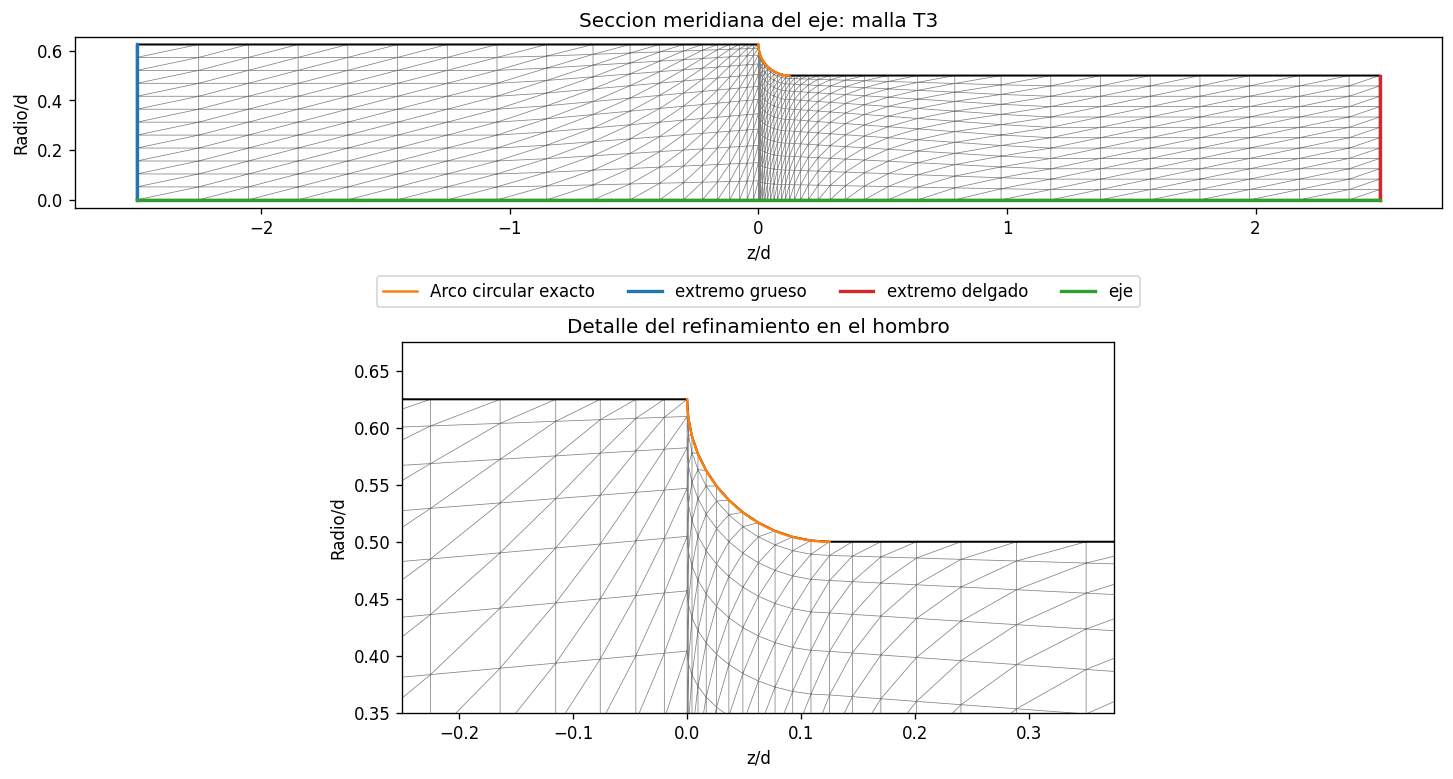

In [6]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)

exterior = coordenadas[bordes["nodos_exterior"]]
contorno = np.vstack(([0, -L_grueso], exterior,
                      [0, L_delgado], [0, -L_grueso]))
angulos = np.linspace(0, np.pi/2, 200)
z_arco = r_transicion*(1-np.cos(angulos))
radio_arco = d/2+r_transicion*(1-np.sin(angulos))

for ax in ejes:
    ax.triplot(coordenadas[:, 1]/d, coordenadas[:, 0]/d,
               conectividad, color="0.5", linewidth=0.45)
    ax.plot(contorno[:, 1]/d, contorno[:, 0]/d, color="black", linewidth=1.2)
    ax.plot(z_arco/d, radio_arco/d, color="tab:orange", linewidth=1.5,
            label="Arco circular exacto")
    ax.set_aspect("equal")
    ax.set_xlabel("z/d")
    ax.set_ylabel("Radio/d")

for nombre, color in [("extremo_grueso", "tab:blue"),
                      ("extremo_delgado", "tab:red"), ("eje", "tab:green")]:
    nodos = bordes["nodos_"+nombre]
    ejes[0].plot(coordenadas[nodos, 1]/d, coordenadas[nodos, 0]/d,
                 color=color, linewidth=2, label=nombre.replace("_", " "))

ejes[0].set_title("Seccion meridiana del eje: malla T3")
ejes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=4)
ejes[1].set_xlim(-0.25, r_transicion/d+0.25)
ejes[1].set_ylim(d/2/d-0.15, D/2/d+0.05)
ejes[1].set_title("Detalle del refinamiento en el hombro")
plt.show()
